---
title: Week 5 Challenge 3 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about box plots.

Use the notebook **Box Plots** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is `taxis`, available from Seaborn.

It records $6433$ taxi trips taken in New York City in March $2019$.

Each row is an observation for a single trip.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| pickup | Datetime | — | Date and time when the trip began. |
| dropoff | Datetime | — | Date and time when the trip ended. |
| passengers | Integer | 0 – 6 | Number of passengers. |
| distance | Continuous | 0 – 36.7 | Trip distance in miles. |
| fare | Continuous | $1 – $150 | Metered fare in US dollars. |
| tip | Continuous | $0 – $33.2 | Tip amount in US dollars. |
| tolls | Continuous | $0 – $70 | Bridge or tunnel toll charges. |
| total | Continuous | — | Total charge (fare + tip + tolls + surcharges). |
| color | Categorical | yellow, green | Cab color; yellow serves Manhattan and airports, green serves outer boroughs. |
| payment | Categorical | credit card, cash | How the trip was paid. |
| pickup_zone | Categorical | — | Named taxi zone where the trip began. |
| dropoff_zone | Categorical | — | Named taxi zone where the trip ended. |
| pickup_borough | Categorical | Manhattan, Queens, Brooklyn, Bronx, Staten Island | Borough where the trip began. |
| dropoff_borough | Categorical | Manhattan, Queens, Brooklyn, Bronx, Staten Island | Borough where the trip ended. |

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
taxis = sns.load_dataset('taxis')
taxis.index.name = 'trip_id'
taxis.info()
taxis.head()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
trip_id,,,,,,,,,,,,,,
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## Tasks

### Task 1

Create a horizontal box plot of `fare`.

Clean it up so that it does not show an unnecessary bounding box.

Describe the shape of the distribution. Is it symmetric or skewed? Are there visible outliers?

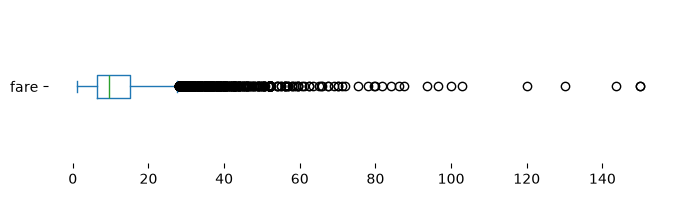

In [3]:
taxis.fare.plot.box(vert=False, figsize=(8, 2))
sns.despine(left=True, bottom=True)
plt.show()

**Answer**: The distribution is strongly right-skewed.

The box is compressed near the left of the axis, indicating that most fares are inexpensive.

A long trail of individual outlier dots extends to the right, as far as $\$150$.

A typical fare costs around $\$10$, but a small number of trips are far more expensive.

### Task 2

Compute $Q1$, $Q3$, the $IQR$, and Tukey's fences for `fare`.

Count how many trips fall outside the fences.

What do you notice about the lower fence?

Hint:
```python
Q1, Q3 = taxis.fare.quantile([.25, .75])
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
```

In [18]:
S = taxis.fare

Q1, Q3 = S.quantile([.25, .75])
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = S[(S < lower) | (S > upper)].to_list()

print(f'Q1           {Q1}')
print(f'Q3           {Q3}')
print(f'IQR          {IQR}')
print(f'Lower fence  {lower:.2f}')
print(f'Upper fence  {upper:.2f}')
print(f'Outliers     {len(outliers)} ({len(outliers)/len(taxis)*100:.1f}%)')
print(f'\nBelow lower fence: {(taxis.fare < lower).sum()}')

Q1           6.5
Q3           15.0
IQR          8.5
Lower fence  -6.25
Upper fence  27.75
Outliers     592 (9.2%)

Below lower fence: 0


**Answer**: 
- $Q1 = 6.5$
- $Q3 = 15.0$
- $IQR = 8.5$

The min value falls at $-6.25$.

This is **negative** — an impossible fare.

No trip can cost less than nothing, so no trip is ever flagged as a low outlier by Tukey's rule.

All $592$ outliers ($9.2\%$ of trips) are on the high side.

This is what Tukey's rule does to a variable that is bounded below and strongly right-skewed: the rule places a symmetric fence around an asymmetric box, making the lower fence meaningless.

### Task 3

Compare `fare` across the values of `pickup_borough` by creating a wide table and drawing horizontal box plots sorted by median.

Which borough has the highest median fare?

In [19]:
fare_by_borough = taxis.pivot(columns='pickup_borough', values='fare')
fare_by_borough

pickup_borough,NaN,Bronx,Brooklyn,Manhattan,Queens
trip_id,,,,,
0,NaN,NaN,NaN,7.0,NaN
1,NaN,NaN,NaN,5.0,NaN
2,NaN,NaN,NaN,7.5,NaN
3,NaN,NaN,NaN,27.0,NaN
4,NaN,NaN,NaN,9.0,NaN
...,...,...,...,...,...
6428,NaN,NaN,NaN,4.5,NaN
6429,NaN,NaN,NaN,NaN,58.0
6430,NaN,NaN,16.0,NaN,NaN


In [20]:
sorted_cols = fare_by_borough.median().sort_values().index.dropna()
sorted_cols

Index(['Manhattan', 'Brooklyn', 'Bronx', 'Queens'], dtype='str', name='pickup_borough')

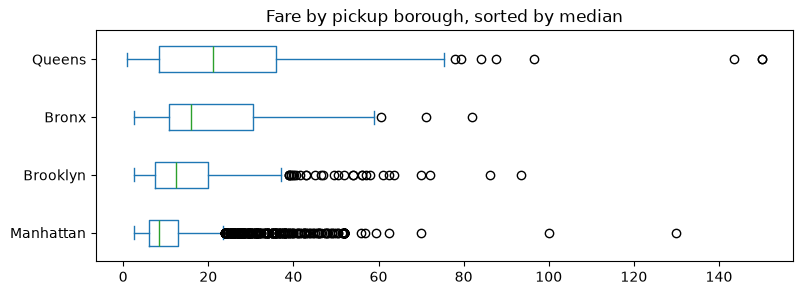

In [21]:
fare_by_borough[sorted_cols].plot.box(vert=False, figsize=(9, 3))
plt.title('Fare by pickup borough, sorted by median')
plt.show()

**Answer**: The medians run Manhattan ($\approx\$8.50$), Brooklyn ($\approx\$12.50$), Bronx ($\approx\$16.00$), Queens ($\approx\$21.00$).

Manhattan has the lowest median because most Manhattan trips are short cross-town or downtown runs.

Queens has the highest median, reflecting the longer distances typical of outer-borough travel — and, as we will see in Task 5, the influence of airport flat fares.

### Task 4

Every box in the plot from Task 3 is drawn at the same width, regardless of how many trips contributed to it.

How many trips does each borough supply?

Is equal-width boxes a limitation of box plots?

In [22]:
fare_by_borough.count().sort_values(ascending=False)

pickup_borough
Manhattan    5268
Queens        657
Brooklyn      383
Bronx          99
NaN            26
dtype: int64

In [23]:
taxis.pickup_borough.value_counts()

pickup_borough
Manhattan    5268
Queens        657
Brooklyn      383
Bronx          99
Name: count, dtype: int64

**Answer**: Manhattan contributes $5268$ trips, Queens $680$, Brooklyn $370$, and the Bronx only $99$.

The box plot gives no indication of this. A box derived from $5268$ trips is far more reliable than one derived from $99$, but both are drawn identically.

This is a genuine limitation of the standard box plot: it shows shape and location but not sample size. 

A violin plot or a beeswarm plot would make the group sizes visible.

### Task 5

Filter the data to trips that began in Queens.

Draw a histogram and a horizontal box plot of `fare` in two plots on the same figure sharing the same x axis.

What does the histogram reveal that the box plot alone does not?

Hint:
```python
fig, ax = plt.subplots(2, 1, height_ratios=[2, 1], sharex=True)
```

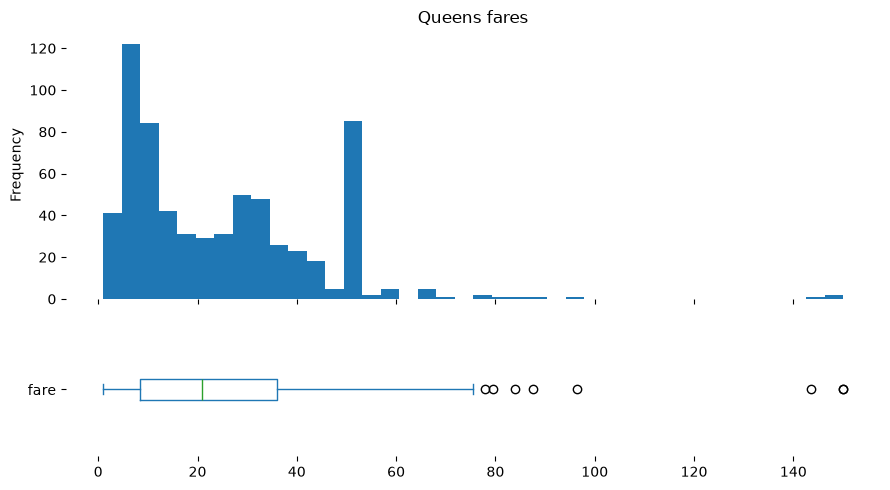

In [24]:
queens = taxis[taxis.pickup_borough == 'Queens'].fare

fig, ax = plt.subplots(2, 1, height_ratios=[2, 1], sharex=True, figsize=(9, 5))
queens.plot.hist(ax=ax[0], bins=40, title='Queens fares')
queens.plot.box(ax=ax[1], vert=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Answer**: The box plot shows a wide box from roughly $\$8$ to $\$36$, with the median near $\$21$.

Read alone, it suggests a single broad distribution of fairly expensive trips.

The histogram shows this is wrong. 

There are **two distinct populations**: a cluster of cheap local runs costing under $\$15$, and a sharp spike of trips at exactly $\$52$, with very little in between.

The median of $\$21$ sits between the two clusters and describes neither of them.

This is the fundamental limitation of the box plot: it can only describe one distribution per box. When there are two populations hidden inside one group, the summary statistics mislead.

### Task 6

The box plots in Task 3 show a cluster of outlier dots near $\$52$ for Manhattan pickups.

What are those trips?

Use the data to investigate your hypothesis.

In [25]:
manhattan = taxis[taxis.pickup_borough == 'Manhattan']
flat_fare = manhattan[manhattan.fare == 52.0]

print(f'Manhattan trips at exactly $52: {len(flat_fare)}')
print()
print(flat_fare.dropoff_borough.value_counts())

Manhattan trips at exactly $52: 48

dropoff_borough
Queens       43
Manhattan     5
Name: count, dtype: int64


**Answer**: Of the $48$ Manhattan trips that cost exactly $\$52$, $43$ end in Queens — where JFK Airport is located.

New York City sets a flat fare of $\$52$ for trips between Manhattan and JFK, so every one of those trips costs the same regardless of origin, distance, or traffic.

The box plot did its job well here: the flat fare sits far outside the normal range for a Manhattan pickup, Tukey's rule correctly flags it, and the tight cluster of dots at a single x-value signals that something systematic — not random variation — is at work.

### Bonus

The whiskers in these plots extend using Tukey's $1.5 \times IQR$ rule, which is the default.

Redraw the borough box plots three times — once with the default rule, once with whiskers reaching the full data range, and once at the $5$th and $95$th percentiles.

How does the number of visible outlier points change?

Hint: `.plot.box()` accepts a `whis` argument. It can be a multiplier (e.g. `1.5`) or a pair of percentiles (e.g. `(5, 95)`).

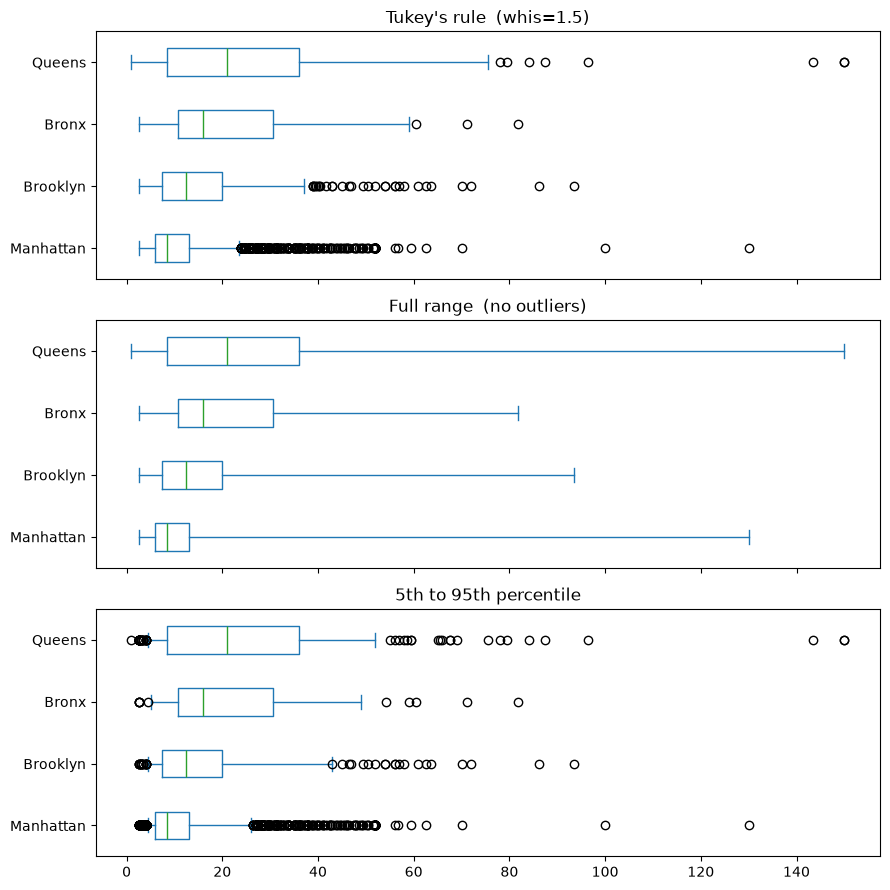

In [26]:
fig, ax = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

fare_by_borough[sorted_cols].plot.box(ax=ax[0], vert=False, title="Tukey's rule  (whis=1.5)")
fare_by_borough[sorted_cols].plot.box(ax=ax[1], vert=False, whis=(0, 100), title='Full range  (no outliers)')
fare_by_borough[sorted_cols].plot.box(ax=ax[2], vert=False, whis=(5, 95), title='5th to 95th percentile')

plt.tight_layout()
plt.show()

**Answer**: Tukey's rule flags $592$ outliers across the entire dataset.

Extending the whiskers to the full range eliminates all outlier points — every observation falls between the whiskers by construction, so nothing can be flagged.

The $5$th/$95$th percentile convention flags roughly $10\%$ of the data by definition, since those percentiles are its cutoffs.

All three plots use identical data. The number of apparent outliers is entirely a function of the whisker convention applied, and none of the three plots announces which convention produced it.

A reader who is told that $9.2\%$ of these trips are outliers has learned as much about the analyst's choice of rule as about the trips.